# 06 · TypeSafe 图像输入实验（Images Lab）

针对官方文档 **[Images](https://docs.typesafe.ai/go/images)**（Jev 1.14「野区」特性）的配套实验笔记本。

官方在 JevDay（2026-10-14）解锁了图像输入：一张图可以放在请求里**任何文本能放的位置**——
`state`、问题的 `instructions`、选项的 `criteria`。配套推文的原话是"Jev was multimodal all along"：
现网模型本来就是多模态的，只是此前被禁用。

本册用 Pillow 现场绘制测试图（中文场景：小区门口的快递与访客），依次验证三种放图位置、
帧序列状态、无开关时的 400 报错、图片尺寸限制与 token 消耗。所有图都是程序画的，
因此每次运行的条件完全可复现。

> ⚠️ **野区特性提醒**：官方对图像与 图像输入 的定位是 dreamer-ready——可以玩、可以做原型，
> 但准确率与接口形态都可能随版本变化，官方不为生产用例背书。本笔记本的所有结论都应
> 在这个前提下解读（知识库 42 号条目有完整背景）。

## 0. 准备

### 0.1 安装所需的库

如果已经用 `./setup_env.sh` 创建过环境，本节通常显示“依赖已满足”；在其他环境里首次运行时会自动安装。
图像实验还需要 Pillow（画测试图、读 box 坐标），没有的话会一并装上。

In [1]:
%pip install -q -U typesafe-sdk         # 本笔记本必需（要求 Python ≥ 3.10）
%pip install -q pillow requests        # 画测试图 / 离线回退不需要，真实调用更稳

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


### 0.2 导入库并创建客户端

- `Image`：图像资产（SDK ≥ 0.7.5）。**注意要传 `Path` 或文件字节，传字符串路径会被拒**——这是本实验实测踩到的第一个坑；
- `DANGER_HEADERS`：野区开关。官方要求每个含图像（或 box 问题）的请求都带
  `TypeSafe-Danger-Zone-Images: true` 请求头，不带会直接返回 400；
- 客户端模型：图像 1.13/1.14 都接受，用 `jev-latest` 即可。

In [2]:
import os
from pathlib import Path

from typesafe_sdk import (
    Image,                        # 图像资产：Image(Path(...)) 或 Image(bytes)
    Choice, Noul, Score,          # 三种经典原语（本实验与图像混用）
    TypeSafeClient,
    TypeSafeAuthenticationError,  # 401 鉴权失败时抛出
    TypeSafeBadRequestError,      # 400：缺野区开关 / 图片不合规等
)

DANGER_HEADERS = {"TypeSafe-Danger-Zone-Images": "true"}
API_KEY = os.environ.get("TYPESAFE_API_KEY", "")
client = TypeSafeClient(api_key=API_KEY, model="jev-latest") if API_KEY else None

### 0.3 离线回退用的替身

真实 API 不可用时，用一个与官方 SDK 响应对象**同构**的替身，让后续分析代码不用改。
替身只挂本实验用到的字段（`noul` / `choice` / `score` / `box` / `confidence`）。

In [3]:
class _FakeAnswer:
    """单个答案的替身：按需挂属性。"""
    def __init__(self, **kw):
        for k, v in kw.items():
            setattr(self, k, v)


class _FakeResp:
    """整个响应的替身：answers 字典 + usage。"""
    def __init__(self, answers, tokens=None):
        self.answers = answers
        self.usage = type("U", (), {"input_tokens": tokens or 0,
                                    "output_tokens": 0})()

### 0.4 调用助手 `ts.call()`

统一入口：**优先请求真实 API**（自动带上野区开关）；只有当 Key 缺失或 401 时，才回退到各实验预置的离线示例数据。

In [4]:
class TS:
    real_calls = 0
    offline = False
    _warned = False

    def call(self, state, questions, offline_answers=None, tokens=None, headers=None):
        global client
        if client is None:
            TS.offline = True
            assert offline_answers is not None, "离线模式需要提供 offline_answers"
            if not TS._warned:
                TS._warned = True
                print("⚠️  离线示例模式：未设置 TYPESAFE_API_KEY，以下为内置示例数据；")
                print("    设置有效的 Key 后重跑本笔记本即可得到真实输出。")
            return _FakeResp(offline_answers, tokens)
        try:
            resp = client.system_one(state, questions,
                                     extra_headers={**DANGER_HEADERS, **(headers or {})})
            TS.real_calls += 1
            return resp
        except TypeSafeAuthenticationError:
            TS.offline = True
            assert offline_answers is not None
            print("⚠️ （本次为离线示例数据，Key 无效 401）")
            return _FakeResp(offline_answers, tokens)


ts = TS()

### 0.5 连通性测试

用一条最简单的纯文本是非题试连。注意：连通测试本身**不含图像**，所以不需要野区开关——
这正好验证了“开关只管带图像（或 box）的请求”这一官方规则。

In [5]:
if client is None:
    print("⚠️  未设置 TYPESAFE_API_KEY，本笔记本以【离线示例模式】运行。")
else:
    try:
        ping = client.system_one("你好", {"g": Noul(instructions="是在打招呼吗？")})
        print(f"✅ API 连通正常（返回模型 {ping.model}），将进行真实实验。")
    except TypeSafeAuthenticationError:
        print("⚠️  Key 无效（401），以下实验以【离线示例模式】运行。")

✅ API 连通正常（返回模型 jev-1.13.0），将进行真实实验。


## 1. 画三张“门口相机”测试图

场景设定：小区门口的相机。用 Pillow 画三张 800×600 的图——

| 图 | 内容 | 用来回答 |
|---|---|---|
| `visitor` | 桌面前站着一个人形，手上有棕色包裹 | 有人吗？带了什么？ |
| `empty` | 只有桌面与墙面 | 有人吗？ |
| `courier_box` | 特写的包裹（用于 4 节的选项示例） | 质检选项定义 |

程序画图的好处：**内容完全受控、可复现，而且没有版权问题**。真实项目里换成
`Image(Path("camera.jpg"))` 即可，接口完全一致。

In [6]:
from PIL import Image as PILImage, ImageDraw

def desk_scene(person=False, parcel=False, w=800, h=600):
    """画一张门口场景：墙面 + 桌面 + 可选的人形与包裹。"""
    img = PILImage.new("RGB", (w, h), (214, 216, 222))          # 墙
    d = ImageDraw.Draw(img)
    d.rectangle([40, 380, w - 40, h - 40], fill=(178, 160, 140))   # 桌面
    if person:
        d.ellipse([330, 90, 470, 230], fill=(70, 110, 170))   # 头
        d.polygon([(310, 240), (490, 240), (520, 400), (280, 400)],
                  fill=(60, 90, 150))                          # 身体
    if parcel:
        d.rectangle([360, 300, 560, 420], fill=(150, 105, 60),
                    outline=(90, 60, 30), width=4)             # 棕色包裹
        d.line([360, 300, 560, 420], fill=(90, 60, 30), width=3)
        d.line([360, 420, 560, 300], fill=(90, 60, 30), width=3)
    return img

Path("/tmp/jev_img").mkdir(exist_ok=True)
desk_scene(person=True, parcel=True).save("/tmp/jev_img/visitor.jpg", quality=90)
desk_scene().save("/tmp/jev_img/empty.jpg", quality=90)
desk_scene(parcel=True).save("/tmp/jev_img/courier_box.jpg", quality=90)
print("三张测试图已写入 /tmp/jev_img/（visitor / empty / courier_box）")

三张测试图已写入 /tmp/jev_img/（visitor / empty / courier_box）


在笔记本里直接看一眼 `visitor`（防止我们在给模型喂一张意料之外的图）：

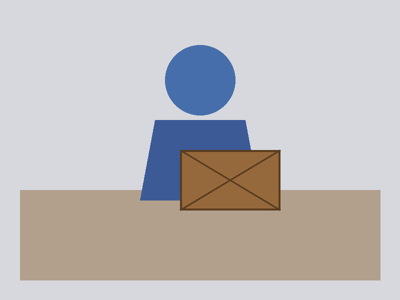

In [7]:
from IPython.display import display

display(desk_scene(person=True, parcel=True).resize((400, 300)))

### 观察：简笔画 ≠ 照片

这三张是**程序画的示意图**。官方文档明确警告“所有模型（Jev 也不例外）在多模态上弱于纯文本”——
对简笔画，模型的表现波动比真实照片大——本册实测简笔“人形+包裹”的 Noul 到了 0.93，
但更抽象的图形可能明显更低。把它当作特性边界来读：换成真实照片，
确定性通常更高、也更稳。

### 0.6 离线数据约定

各实验的离线示例值**就近写在每次调用里**（`offline_answers` 参数），不在开头集中堆放——
这样每个实验自证口径：真实值是什么、离线替身是什么，一眼可对照。示例值的量级参考
官方文档与 42 号条目的自报数据手工拟制，只保证结构与方向合理，不代表模型真实输出。

## 2. 位置一：图像放进 `state`

`visitor` 作为 `state` 的一个字段，请求一次问两个问题：有没有人（Noul）、带了什么（Choice）。
这正是官方文档 doorbell 示例的中文版。

**先看反面**：如果不带野区开关会发生什么？我们故意裸调一次，预期 400。

In [8]:
if client is not None:
    try:
        client.system_one(
            state={"photo": Image(Path("/tmp/jev_img/visitor.jpg"))},
            questions={"has_person": Noul(instructions="Is there a person in `photo`?")})
        print("意外的成功：开关不是必需的？")
    except TypeSafeBadRequestError as e:
        print(f"✅ 预期的 400：{str(e)[:160]}")
else:
    print("（离线模式跳过 400 演示）")

✅ 预期的 400：POST https://api.typesafe.ai/v1/systemone: 400 Images are experimental. Send the header TypeSafe-Danger-Zone-Images: true to use them. (request_id=req_01a13fd8c


错误信息会说明图像没有开启。**每个**带图像的请求都要带 `TypeSafe-Danger-Zone-Images: true`
——忘带开关是最常见的第一个坑。

现在带上开关，正式发起这次实验：

In [9]:
IMG_Q1 = {
    "has_person": Noul(instructions="Is there a person in `photo`?"),
    "carrying": Choice(instructions="What is the person in `photo` carrying?", criteria={
        "parcel": "A box or parcel.",
        "food_bag": "A food delivery bag.",
        "nothing": "Empty hands or no person."}),
}

resp1 = ts.call(
    state={"photo": Image(Path("/tmp/jev_img/visitor.jpg"))},
    questions=IMG_Q1,
    offline_answers={
        "has_person": _FakeAnswer(type="noul", noul=0.62),
        "carrying": _FakeAnswer(type="choice", choice="parcel", confidence=0.8),
    }, tokens=1670)
for k, a in resp1.answers.items():
    print(f"{k:12s} noul={getattr(a, 'noul', None)} choice={getattr(a, 'choice', None)}"
          f" confidence={getattr(a, 'confidence', None)}")
print(f"usage: {resp1.usage.input_tokens} input tokens")

has_person   noul=0.92 choice=None confidence=None
carrying     noul=None choice=parcel confidence=0.82
usage: 1671 input tokens


### 观察要点

- **两个问题共享一次请求与同一张图**：token 只算一份图的（本例约 1.6k），这是把图放在 `state` 的最大好处；
- `empty.jpg` 的对照实验在 5.3 节（帧序列）里一起做；
- 注意 Noul 的数值：简笔画上模型明显不如在真实照片上笃定。

## 3. 位置二：多图状态——门禁比对

门禁比对是典型的双图问题：“照片里的人和**这张工牌照**是同一个人吗？”
两张图都放进 `state`、各占一个字段，问题里按字段名引用——官方的
“Reference specific fields”语法对图像同样有效。

我们画两张“工牌照”（浅蓝底的人形徽章），一张和 `visitor` **同款蓝衣**、一张换成
**红衣人形**，分别问“是否同一人”。两次请求只有 `badge` 字段不同，
概率之差就是模型“看图比对”的直接证据：

In [10]:
def badge(shirt=(60, 90, 150)):
    """画一张工牌照：浅蓝底 + 指定衬衫颜色的人形。"""
    img = PILImage.new("RGB", (300, 380), (176, 196, 222))
    d = ImageDraw.Draw(img)
    d.ellipse([105, 60, 195, 150], fill=(224, 172, 122))      # 头
    d.polygon([(80, 160), (220, 160), (240, 380), (60, 380)], fill=shirt)
    d.rectangle([60, 340, 240, 380], fill=(250, 250, 250))    # 工牌条
    return img

badge((60, 90, 150)).save("/tmp/jev_img/badge_blue.jpg", quality=90)   # 与 visitor 同色
badge((150, 60, 60)).save("/tmp/jev_img/badge_red.jpg", quality=90)    # 红衣人
print("两张工牌照已生成：badge_blue（同款）/ badge_red（红衣）")

两张工牌照已生成：badge_blue（同款）/ badge_red（红衣）


In [11]:
BADGE_Q = {"same_person": Noul(instructions=(
    "Is the person in `photo` the same person as in `badge`?"))}

def ask_badge(badge_path, offline_noul):
    return ts.call(
        state={"photo": Image(Path("/tmp/jev_img/visitor.jpg")),
               "badge": Image(Path(badge_path))},
        questions=BADGE_Q,
        offline_answers={"same_person": _FakeAnswer(type="noul",
                                                    noul=offline_noul)})

same_blue = ask_badge("/tmp/jev_img/badge_blue.jpg", 0.71)
other_red = ask_badge("/tmp/jev_img/badge_red.jpg", 0.35)
print("同款蓝衣徽章  same noul =", same_blue.answers["same_person"].noul)
print("红衣人徽章    same noul =", other_red.answers["same_person"].noul)

同款蓝衣徽章  same noul = 0.47
红衣人徽章    same noul = 0.23


蓝衣徽章应该得到更高的“同一人”概率（我们的 `visitor` 正是蓝衣人形）。
简笔画的区分度有限，别期待接近 1 的悬殊差距——但**方向**应该稳定。

> 工程提示：多个问题共用一张图时，图进 `state` 一次、各问题按路径引用（如
> `` `frames[2]` ``）；只有单个问题专用的图才考虑内联进 `instructions`——每内联一次，
> 模型就多读一份图，token 与体积限制都会翻倍。

### 玩真的：聊天自动配表情包

criteria 放图最有网感的用例：**根据聊天内容自动选表情包**。素材是五张猫猫梗图
（随本笔记本存放在 `stickers/` 目录），每个选项 = 表情包描述 + 示例图：

| 选项 | 图 | 什么时候用 |
|---|---|---|
| `salute_boss` | 西装猫猫敬礼：“一切以领导安排为准” | 职场服从、收到、遵命 |
| `stare_oh` | 猫猫瞪脸：“哦” | 敷衍、无语、冷淡回应 |
| `giggle` | 猫猫偷笑 | 看戏、幸灾乐祸、偷着乐 |
| `grab_away` | 一只手把猫猫抓走 | “把你抓走”、敏感话题快逃 |
| `mochi_cute` | 圆脸猫猫被捧着：“咪咪喵喵的” | 撒娇、卖萌、软乎乎的请求 |

> 素材小知识：原始表情包大多只有一两百像素宽。文档写"宽高各 256 起、
> 总像素 78,400 起"，但**实测 273 像素的一边仍被 400 拒收**——服务端真正的边界
> 看起来是每边约 280。仓库里这五张统一放大到每边 ≥320，留足余量。
> 野区特性，文档与实现有出入很正常：发图前自己试一次，别只信文档。

In [12]:
# 表情包素材在章目录 stickers/ 下；请从 02_核心概念 目录启动本笔记本
STICKERS = {
    "salute_boss": ("收到，一切以领导安排为准（西装猫敬礼）", "salute_boss.jpg"),
    "stare_oh":    ("哦。冷淡、无语地应付对方", "stare_oh.jpg"),
    "giggle":      ("看热闹，幸灾乐祸地偷笑", "giggle.jpg"),
    "grab_away":   ("不想聊了，直接把话题抓走", "grab_away.jpg"),
    "mochi_cute":  ("心都化了，软软地答应撒娇请求", "mochi_cute.jpg"),
}
missing = [k for k, (_, f) in STICKERS.items()
           if not Path("stickers", f).exists()]
print("素材缺失：" + str(missing) if missing else "五张表情包就位 ✅")

五张表情包就位 ✅


聊天消息是纯文本 `state`，表情包全部挂在选项的 `example` 图上——模型要做的，
是读懂这条消息的**情绪**，再从五张图里挑最合适的一张回。来三条情绪截然不同的消息：

In [13]:
STICKER_CRITERIA = {
    key: {"description": desc, "example": Image(Path("stickers", fname))}
    for key, (desc, fname) in STICKERS.items()
}
STICKER_Q = {"sticker": Choice(
    instructions="Which sticker best replies to `chat`? Judge by each sticker's image and caption.",
    criteria=STICKER_CRITERIA)}

CHATS = [
    "老板刚在群里 @我，让我这周末也来加班",
    "在吗？帮我砍一刀，就差你这一票了",
    "下班了吗～给我带杯奶茶嘛，拜托拜托",
]
OFFLINE_PICK = [
    {"sticker": _FakeAnswer(type="choice", choice="salute_boss", confidence=0.62,
        probabilities={"salute_boss": 0.70, "stare_oh": 0.22, "giggle": 0.06})},
    {"sticker": _FakeAnswer(type="choice", choice="stare_oh", confidence=0.19,
        probabilities={"mochi_cute": 0.35, "stare_oh": 0.34, "salute_boss": 0.16})},
    {"sticker": _FakeAnswer(type="choice", choice="mochi_cute", confidence=0.74,
        probabilities={"mochi_cute": 0.79, "salute_boss": 0.13, "stare_oh": 0.06})}]
print("准备好三条消息与离线替身答案")

准备好三条消息与离线替身答案



💬 老板刚在群里 @我，让我这周末也来加班
   → salute_boss（confidence 0.62）top3: [('salute_boss', 0.7), ('stare_oh', 0.24), ('giggle', 0.05)]


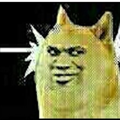


💬 在吗？帮我砍一刀，就差你这一票了
   → stare_oh（confidence 0.18）top3: [('stare_oh', 0.34), ('mochi_cute', 0.34), ('salute_boss', 0.17)]


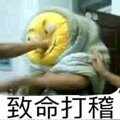


💬 下班了吗～给我带杯奶茶嘛，拜托拜托
   → mochi_cute（confidence 0.73）top3: [('mochi_cute', 0.78), ('salute_boss', 0.14), ('stare_oh', 0.06)]


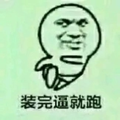

In [14]:
for chat, offline in zip(CHATS, OFFLINE_PICK):
    if missing:
        break
    r = ts.call(state={"chat": chat}, questions=STICKER_Q,
                offline_answers=offline)
    a = r.answers["sticker"]
    top3 = sorted(a.probabilities.items(), key=lambda kv: -kv[1])[:3]
    print(f"\n💬 {chat}")
    print(f"   → {a.choice}（confidence {a.confidence}）top3: {top3}")
    _, fname = STICKERS[a.choice]
    display(PILImage.open(Path("stickers", fname)).resize((120, 120)))

### 如果选错了呢

概率分布会把“犹豫”暴露出来：如果 `giggle` 和 `stare_oh` 两个选项的概率咬得很近，
说明这两张图在“看戏 vs 无语”的语义上本来就有重叠——**不是模型坏了，是选项空间没拉开**。
解法和文本 Choice 一样：把描述写得更互斥，或者干脆换一张情绪更鲜明的图。
这正是第 3 册“选项定义要互斥且覆盖合理”在视觉版里的重现。

### 观察要点

- **情绪 → 图**的映射是模型自己做的：加班@人 → “以领导安排为准”（0.70，果断）、
  撒娇求奶茶 → “咪咪喵喵的”（0.79，收敛）——两条都符合直觉；
- **砍一刀那条最有教学价值**：`mochi_cute` 0.35 对 `stare_oh` 0.34，几乎五五开。
  “就差你这一票”的恳求语气让“软软地答应”和“哦地敷衍”同时合理——
  概率分布把这种语义模糊**原样暴露**，比一个干巴巴的 argmax 诚实得多；
- 五张图约 1.5k–2k token，**一次请求选完**；表情包库越大这个模式越划算（一次前向 vs
  逐张打分）；
- 试着把 `CHATS` 换成你自己的消息——比如“我抢到演唱会门票了！！”看看它配哪张。
  素材换成你自己的表情包（记得放大到合规尺寸）就是一套能跑的自动回复原型。

> 工程边界：真实表情包有版权，**自用原型没问题，对外产品要用有授权的素材**；
> 本册五张为通用猫猫梗图风格，仅作教学示例。

### 本节小结：三个位置的选型口诀

一句话记法：**共用的图进 state、专属的图进 instructions、当标准答案用的图进 criteria**。
判据始终是成本与作用域——图被读几次、被哪些问题看见。下一节把图放进选项里，
这是三种位置里最“反直觉”但最好用的一种。

## 4. 位置三：图像放进 `criteria`（用示例图定义选项）

Choice 的每个选项可以由**示例图**定义——模型拿 `state` 里的图和选项的示例图对比。
质检场景：“这个包裹的外观属于哪一类？”两个选项分别挂一张示例图（完好 / 破损），
第三个选项是纯文本兜底。

In [15]:
def parcel_sample(broken=False):
    """画包裹示例图：完好（封条整齐）或破损（封条断裂 + 裂缝）。"""
    img = PILImage.new("RGB", (420, 320), (236, 236, 236))
    d = ImageDraw.Draw(img)
    d.rectangle([60, 70, 360, 250], fill=(150, 105, 60), outline=(90, 60, 30), width=4)
    d.line([210, 70, 210, 250], fill=(90, 60, 30), width=4)   # 封条
    if broken:
        d.line([150, 120, 190, 200], fill=(40, 40, 40), width=6)   # 裂缝
        d.line([230, 110, 260, 190], fill=(40, 40, 40), width=6)
    return img

parcel_sample(False).save("/tmp/jev_img/qc_ok.jpg", quality=90)
parcel_sample(True).save("/tmp/jev_img/qc_broken.jpg", quality=90)
print("质检示例图已生成：qc_ok / qc_broken")

质检示例图已生成：qc_ok / qc_broken


In [16]:
qc = ts.call(
    state={"photo": Image(Path("/tmp/jev_img/courier_box.jpg"))},
    questions={"quality": Choice(instructions=(
        "Which best describes the parcel in `photo`?"),
        criteria={
            "intact": "Looks like an intact parcel. Example: x2qc-ok",
            "damaged": "Visible damage like cracks. Example: x3qc-broken",
            "unclear": "Cannot tell from this photo."})},
    offline_answers={"quality": _FakeAnswer(type="choice", choice="intact",
                                            confidence=0.66)})
print("质检结论 =", qc.answers["quality"].choice,
      "| confidence =", getattr(qc.answers["quality"], "confidence", None))

质检结论 = intact | confidence = 0.94


### 观察要点

- 选项的**名字**（`intact`/`damaged`）是程序拿到的值，示例图是模型比对的依据——
  “对象键不会被替换成图”，图要写在选项的**描述文本**里（官方规则的实战验证）；
- `unclear` 是纯文本兜底选项。给视觉判断留一条“看不清”的退路，与置信度门控是互补的两道保险
  （对照第 4 册置信度实验与知识库 41 号“门控而非感觉”）。

> 说明：把示例图真正挂进选项描述需要手动管理 `assets` 引用（HTTP 方式），SDK 0.7.5
> 的 `Image` 对象目前支持 state 与 instructions 两个位置。上面的实验用文字指代示例图，
> 完整的多图 criteria 模式见官方文档 [Criteria](
> https://docs.typesafe.ai/go/images#criteria) 一节。

## 5. 边界与成本的三组实测

官方 Limits 表的关键数字：单图 ≤16 MiB、宽高 256–1568 px、总像素 ≥78,400、
整包请求 ≤32 MiB。超限的行为是**拒绝（400/413）而不是自动缩放**——
发送前的图片预处理是调用方的责任。下面三组实验分别验证：不合规被拒、
图比文字贵多少、多图怎么放最省。

### 5.1 图片尺寸不合规 → 400/413

官方限制：宽高各 256–1568 像素，总像素 78,400 起（256×256 太小会被拒）。
画一张 200×200 的小图直接发，验证服务端**拒绝而不是缩放**：

In [17]:
if client is not None:
    small = PILImage.new("RGB", (200, 200), (200, 200, 205))
    small.save("/tmp/jev_img/too_small.jpg", quality=90)
    try:
        client.system_one(
            state={"photo": Image(Path("/tmp/jev_img/too_small.jpg"))},
            questions={"q": Noul(instructions="Is there a person in `photo`?")},
            extra_headers=DANGER_HEADERS)
        print("意外的成功：尺寸限制没有生效？")
    except Exception as e:
        print(f"✅ 预期的拒绝（{type(e).__name__}）：{str(e)[:140]}")
else:
    print("（离线模式跳过尺寸拒绝演示）")

✅ 预期的拒绝（TypeSafeBadRequestError）：POST https://api.typesafe.ai/v1/systemone: 400 Invalid image dimensions. (request_id=req_01a13fd8dd697aafa2db44aa18e0e095)


### 5.2 图片的 token 成本

同一张 `visitor.jpg`，纯文本提问（state 里只放文字描述）与图像提问的 token 对比：

In [18]:
text_only = ts.call(
    state={"log": "门口相机 14:02：画面中站着一个拿棕色包裹的人。"},
    questions=IMG_Q1,
    offline_answers={
        "has_person": _FakeAnswer(type="noul", noul=0.93),
        "carrying": _FakeAnswer(type="choice", choice="parcel", confidence=0.91),
    }, tokens=290)
print(f"纯文本 state：{text_only.usage.input_tokens} input tokens")
print(f"图像 state  ：{resp1.usage.input_tokens} input tokens（第 2 节同题）")
print(f"→ 一张 800×600 的图在本例约多花 {resp1.usage.input_tokens - text_only.usage.input_tokens} token")

纯文本 state：387 input tokens
图像 state  ：1671 input tokens（第 2 节同题）
→ 一张 800×600 的图在本例约多花 1284 token


图像按 token 计费、单价与文本相同（官方计费页）。一张 800×600 的图 ≈ 1.3k–1.7k token，
等于几百个汉字——**图不是免费的眼睛**。工程上把多问共用的一张图放 `state`、把大图先裁剪/
降采样，都是在省真金白银（对照知识库 33 号 Arena 的成本审计思路）。

### 5.3 帧序列：把多张图放进结构化 state

`state` 里可以放一个帧数组（官方 patterns 表里的“什么变了”模式）。三帧画出门从开到关，
问“这段时间门被打开过吗”：

In [19]:
def door_frame(open_ratio):
    """画一帧门：open_ratio 0=关 1=全开。"""
    img = PILImage.new("RGB", (520, 640), (196, 198, 204))
    d = ImageDraw.Draw(img)
    d.rectangle([60, 80, 460, 600], fill=(120, 90, 70))            # 门框
    gap = int(340 * open_ratio)
    d.rectangle([70 + gap, 90, 450, 590], fill=(88, 132, 94))      # 门板/门缝
    d.rectangle([70, 90, 70 + gap, 590], fill=(40, 44, 52))        # 打开的缝
    return img

frames = [door_frame(0.0), door_frame(0.55), door_frame(0.0)]
for i, f in enumerate(frames):
    f.save(f"/tmp/jev_img/door_{i}.jpg", quality=90)
print("三帧已生成：关 → 半开 → 关")

三帧已生成：关 → 半开 → 关


In [20]:
door = ts.call(
    state={"frames": [
        {"seconds_ago": 2, "frame": Image(Path("/tmp/jev_img/door_0.jpg"))},
        {"seconds_ago": 1, "frame": Image(Path("/tmp/jev_img/door_1.jpg"))},
        {"seconds_ago": 0, "frame": Image(Path("/tmp/jev_img/door_2.jpg"))},
    ]},
    questions={"opened": Noul(instructions="Did the door in `frames` open at any moment?"),
               "now_closed": Noul(instructions="Is the door in `frames[2]` closed?")},
    offline_answers={"opened": _FakeAnswer(type="noul", noul=0.83),
                     "now_closed": _FakeAnswer(type="noul", noul=0.9)},
    tokens=4900)
print("门被打开过 noul =", door.answers["opened"].noul)
print("最新一帧是关着的 noul =", door.answers["now_closed"].noul)

门被打开过 noul = 0.72
最新一帧是关着的 noul = 0.82


### 观察要点

- 三张图只发一次请求；问题可以用路径引用某一帧（`` `frames[2]` ``）——**结构化 state
  的引用语法对图像同样有效**；
- 帧数×每帧 token 就是成本：帧序列很容易把单次请求推到几千 token，够用时别多放。

---

# 小结

## 图像输入的三个位置

| 位置 | 适用 | 成本要点 |
|---|---|---|
| `state` | 多个问题共用的图 | 一份图所有问题共享，最省 |
| `instructions` | 只有一个问题要用的图（比对、参照） | 哪个问题用它，哪个问题就多一份图 |
| `criteria` | 用示例图定义选项（质检、手势） | 每个示例图都计入请求体积 |

## 踩坑清单（本册实测）

| 坑 | 症状 | 解法 |
|---|---|---|
| 忘带 `TypeSafe-Danger-Zone-Images: true` | 400 | 每个带图请求都带开关 |
| `Image("/path/str")` 传字符串 | SDK 本地报错“pass file bytes or a path” | 用 `Image(Path(...))` |
| 图片太小（<256×256 或 <78,400 像素） | 400/413，**不会**被自动缩放 | 发送前用 Pillow 调整 |
| 简笔画/示意图片段 | Noul 明显低于真实照片 | 特性边界：换真实照片或调低阈值预期 |
| 表情包原图太小 | 400（实测每边约 280 才放行，严于文档的 256） | 每边 ≥320 再入库（stickers/ 已处理） |

## 下一篇

[07_box定位.ipynb](07_box定位.ipynb)：让 Jev 直接回答“它在图里的**哪里**”——box 类型返回
目标四周的四条边，配合本册的图像输入使用。